In [1]:
import cv2
import os

import matplotlib.pyplot as plt
import numpy as np

from torchvision import datasets, transforms
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from tqdm import tqdm

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'using device: {device}')

using device: cuda


# Data Processing

In [3]:
transform=transforms.Compose([
        transforms.Resize((512, 512)),
        transforms.ToTensor(),
    ])
train_dataset = datasets.ImageFolder('./chest_xray/train', transform=transform)
test_dataset = datasets.ImageFolder('./chest_xray/test', transform=transform)
val_dataset = datasets.ImageFolder('./chest_xray/val', transform=transform)

train_dataloader = torch.utils.data.DataLoader(dataset=train_dataset,batch_size=64,shuffle=True,num_workers=8)
test_dataloader = torch.utils.data.DataLoader(dataset=test_dataset,batch_size=64,num_workers=8)
val_dataloader = torch.utils.data.DataLoader(dataset=val_dataset,batch_size=64,num_workers=8)

# Network Modules

In [4]:
hidden_channels = np.array([8, 16, 32, 64, 128, 256, 512, 512])
latent_dims = 1024

In [5]:
in_channels = 3
encoder_network = []

for h_dims in hidden_channels:
    encoder_network.append(
        nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=h_dims,
                kernel_size=3,
                stride=2,
                padding=1,
                ),
            nn.BatchNorm2d(h_dims),
            nn.LeakyReLU(),
        )
    )
    in_channels = h_dims

fc_mu = nn.Linear(2048, latent_dims)
fc_var = nn.Linear(2048, latent_dims)

decoder_network = []

decoder_network.append(nn.Linear(latent_dims, 2048))
decoder_network.append(nn.Unflatten(dim=1, unflattened_size=(512, 2, 2)))

for i in range(len(hidden_channels) - 1):
    decoder_network.append(
        nn.Sequential(
            nn.ConvTranspose2d(
                in_channels=hidden_channels[::-1][i],
                out_channels=hidden_channels[::-1][i+1],
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1,
                ),
            nn.BatchNorm2d(hidden_channels[::-1][i+1]),
            nn.LeakyReLU(),
        )
    )

decoder_network.append(
    nn.Sequential(
        nn.ConvTranspose2d(
            in_channels=hidden_channels[0],
            out_channels=3,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1),
        nn.Tanh()
    )
)

fc_mu.to(device)
fc_var.to(device)
encoder = nn.Sequential(*encoder_network).to(device)
decoder = nn.Sequential(*decoder_network).to(device)

### Sample Forward Pass

In [6]:
sample_data = torch.randn(32, 3, 512, 512).to(device)
encoder_out = encoder(sample_data).flatten(start_dim=1)
encoder_out = fc_mu(encoder_out)

z_sample = decoder(encoder_out)
z_sample.shape
decoder(encoder_out).shape

torch.Size([32, 3, 512, 512])

# Training

In [7]:
networks = [encoder, fc_mu, fc_var, decoder]
optimizer = optim.Adam([p for net in networks for p in net.parameters()], lr=1e-5)
num_epochs = 100

In [ ]:
epoch_losses = []
val_losses = []

for epoch in range(1, num_epochs):
        
    epoch_loss = 0
    val_loss = 0

    for images, _ in tqdm(train_dataloader, desc=f'Epoch {epoch}'):
        for net in networks: net.train()
        images = images.to(device)
        optimizer.zero_grad()

        encoder_output = encoder(images).flatten(start_dim=1)
        mu = fc_mu(encoder_output)
        log_var = fc_var(encoder_output)
        z_sample = mu + torch.randn_like(mu) * torch.exp(0.5* log_var)
        x_reconstruct = decoder(z_sample)

        recons_loss = F.mse_loss(x_reconstruct, images)
        kld_loss = torch.mean(-0.5 * torch.sum(1 + log_var - mu ** 2 - log_var.exp(), dim=1), dim=0)
        loss = recons_loss + 0.001 * kld_loss

        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    for net in networks: net.eval()
    with torch.no_grad():    
        for images, _ in val_dataloader:
            
            images = images.to(device)
            encoder_output = encoder(images).flatten(start_dim=1)
            mu = fc_mu(encoder_output)
            log_var = fc_var(encoder_output)
            z_sample = mu + torch.randn_like(mu) * torch.exp(0.5* log_var)
            x_reconstruct = decoder(z_sample)
    
            recons_loss = F.mse_loss(x_reconstruct, images)
            kld_loss = torch.mean(-0.5 * torch.sum(1 + log_var - mu ** 2 - log_var.exp(), dim=1), dim=0)
            loss = recons_loss + 0.001 * kld_loss

            val_loss += loss.item()

    epoch_losses.append(epoch_loss)
    val_losses.append(val_loss)
            

    print(f'finished epoch {epoch+1}, epoch loss {epoch_loss / len(train_dataloader):.3f} \t val loss {val_loss / len(val_dataloader):.3f}')
    

Epoch 1: 100%|██████████| 82/82 [00:25<00:00,  3.22it/s]


finished epoch 2, epoch loss 0.426 	 val loss 0.405


Epoch 2: 100%|██████████| 82/82 [00:25<00:00,  3.23it/s]


finished epoch 3, epoch loss 0.353 	 val loss 0.359


Epoch 3: 100%|██████████| 82/82 [00:25<00:00,  3.25it/s]


finished epoch 4, epoch loss 0.330 	 val loss 0.342


... (187 outputs left out)

finished epoch 98, epoch loss 0.057 	 val loss 0.060


Epoch 98: 100%|██████████| 82/82 [00:25<00:00,  3.24it/s]


finished epoch 99, epoch loss 0.056 	 val loss 0.058


Epoch 99:  54%|█████▎    | 44/82 [00:14<00:10,  3.60it/s]

## Saving Models

In [16]:
# checkpoint = {
#     'encoder': encoder.state_dict(),
#     'fc_mu': fc_mu.state_dict(),
#     'fc_var': fc_var.state_dict(),
#     'decoder': decoder.state_dict(),
#     'optimizer': optimizer.state_dict(),
# }
# checkpoint_name = './checkpoints/first-save.pth'
# torch.save(checkpoint, checkpoint_name)

checkpoint_name = './first-save.pth'
checkpoint = torch.load(checkpoint_name)
encoder.load_state_dict(checkpoint['encoder'])
fc_mu.load_state_dict(checkpoint['fc_mu'])
fc_var.load_state_dict(checkpoint['fc_var'])
decoder.load_state_dict(checkpoint['decoder'])

<All keys matched successfully>

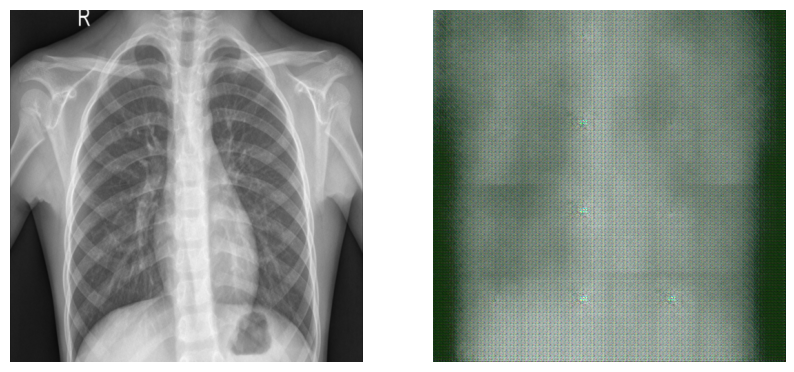

In [22]:
def generate_and_display(images, encoder, fc_mu, fc_var, decoder, device):
    for net in [encoder, fc_mu, fc_var, decoder]: 
        net.eval()
    
    with torch.no_grad():
        images = images.to(device)
        enc_out = encoder(images).flatten(start_dim=1)
        mu = fc_mu(enc_out)
        log_var = fc_var(enc_out)
        
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * log_var)
        recon = decoder(z)
        
    orig = images[0].cpu().permute(1, 2, 0).numpy()
    out = recon[0].cpu().permute(1, 2, 0).numpy()
    
    orig = np.clip(orig, 0, 1)
    out = np.clip(out, 0, 1)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    ax1.imshow(orig, cmap='gray')
    ax1.axis('off')
    ax2.imshow(out, cmap='gray')
    ax2.axis('off')
    plt.show()

data_iter = iter(test_dataloader)
images, _ = next(data_iter)
generate_and_display(images, encoder, fc_mu, fc_var, decoder, device)

In [19]:
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore
import torch

def eval_step(engine, batch):
    with torch.no_grad():
        real = batch[0].to(device)
        z = torch.randn(real.size(0), 1024).to(device)
        fake = decoder(z)
        return fake, real

evaluator = Engine(eval_step)

fid = FID(device=device)
fid.attach(evaluator, "fid")

isc = InceptionScore(device=device, output_transform=lambda x: x[0])
isc.attach(evaluator, "is")

evaluator.run(test_dataloader)
metrics = evaluator.state.metrics

print(f"FID: {metrics['fid']:.4f} \t IS: {metrics['is']:.4f}")

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /home/jjp003/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth
100%|██████████| 104M/104M [00:00<00:00, 168MB/s] 


FID: 0.0021 	 IS: 1.0105
